# Relatório da Análise Exploratória de Dados

**Universidade Estadual de Montes Claros**  
**Especialização em Ciência de Dados**  
**Disciplina:** Trabalho de Conclusão de Curso   
**Aluno:** Luan Silva Gomes 

**Projeto:** Predizer a gravidade de acidentes de trânsito com vítimas em Minas Gerais utilizando dados dos últimos 5 anos, de 2021 a 2026, provenientes da Base de Dados do Painel de Sinistro de Trânsito da Secretaria de Estado de Justiça e Segurança Pública de Minas Gerais, para que o socorro médico possa ser direcionado/priorizado com mais eficiência na resposta da emergência. 

# Importação de Dependências e Configurações Básicas

Os dados brutos estão armazenados no diretório `/data` deste projeto.

In [1]:
import sys
import os 
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data"
if not DATA_DIR.exists() or not DATA_DIR.is_dir():
     raise FileNotFoundError(f"Diretório de dados '{DATA_DIR}' não encontrado") 

In [2]:
from src.preprocessing import (
    get_df_per_data_group,
    display_basic_df_info_per_data_group
)

from src.constants import ALL_YEARS

# Pré-processamento

## 1. Importação e contexto dos dados

A base de dados original está armazenada em uma pasta compartilhada do Google Drive e possui 5 subpastas: Vítimas, Via, Veículo, Ocorrências e Condições. Cada subpasta possui um arquivo .csv para cada ano contendo dados de Janeiro a Dezembro do respectivo ano, com exceção, na data da execução desta análise (06 de Setembro de 2026), para o ano atual que possui dois arquivos, um abrangendo o perídio de Janeiro a Junho e outro de Janeiro a Julho. Neste trabalho, o arquivo utilizado para o ano de 2026 foi o que possui dados de Janeiro a Julho.

Como supracitados, os dados estão separados em 5 grupos: 
- Condições (`condicoes`): condições das vias em que ocorreram os registros
- Ocorrências (`ocorrencias`): dados referentes a cada ocorrência
- Veículo (`veiculo`): veículo envolvido no sinistro
- Via (`via`): informações sobre a via em que aconteceu o fato
- Vitimas (`vitimas`): registros sobre as vitimas envolvidas no acidente

O datset de cada grupo se conecta com o outro através através da propriedade numero_ocorrencia_associado. Esse será o atributo utilizado para unir as instâncias de cada grupo que estão relacionadas com uma única ocorrência. Resultando assim, em um dataframe unificado com os 5 grupos.

Alguns dataset de grupos diferentes possuem colunas de mesmo nome. Para solucionar esse problema, os grupos serão importados com nomes de colunas próprios que seguem o seguinte padrão: prefixo (três primeiras letras do nome do grupo) + nome original da coluna sanitarizado. Um mapeamento com os nomes das colunas pode ser encontrado no diretório: `/src/constants.py`.

In [3]:
df_per_data_group = get_df_per_data_group(DATA_DIR, ALL_YEARS)
display_basic_df_info_per_data_group(df_per_data_group)

/Users/luangomes/Code/road-traffic-accident-severity-prediction-mg/src/preprocessing.py:17: DtypeWarning: Columns (0: oco_latitude_sirgas2000, 1: oco_longitude_sirgas2000) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path, sep=';', header=header, names=columns)
/Users/luangomes/Code/road-traffic-accident-severity-prediction-mg/src/preprocessing.py:17: DtypeWarning: Columns (0: vit_latitude_sirgas2000, 1: vit_longitude_sirgas2000) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path, sep=';', header=header, names=columns)


Data group: condicoes
Números de linhas: 1503336
Número de colunas: 8
Colunas disponíveis:


,Nome da coluna,Tipo da coluna
0,numero_ocorrencia_associado,str
1,con_ano_fato,int64
2,con_mes_numerico_fato,int64
3,con_luminosidade_descricao,str
4,con_condicao_sinalizacao_descricao,str
5,con_tipo_via_descricao,str
6,con_tipo_pavimento_descricao,str
7,con_verificacao,str


Primeiras 5 linhas do DataFrame:


,numero_ocorrencia_associado,con_ano_fato,con_mes_numerico_fato,con_luminosidade_descricao,con_condicao_sinalizacao_descricao,con_tipo_via_descricao,con_tipo_pavimento_descricao,con_verificacao
0,949ad814c910eca5,2012,12,DIA,BOA,PISTA SIMPLES,ASFALTO,949ad814c910eca5-DIA-BOA-PISTA SIMPLES-ASFALTO
1,43fec5bd45ef90b4,2012,12,DIA,NAO HA,PISTA MULTIPLA,ASFALTO,43fec5bd45ef90b4-DIA-NAO HA-PISTA MULTIPLA-ASF...
2,3dc730c6e9d5de07,2012,12,DIA,NAO HA,PISTA SIMPLES,ASFALTO,3dc730c6e9d5de07-DIA-NAO HA-PISTA SIMPLES-ASFALTO
3,474cdcf691cb86dd,2012,12,DIA,BOA,PISTA SIMPLES,ASFALTO,474cdcf691cb86dd-DIA-BOA-PISTA SIMPLES-ASFALTO
4,bfc11a23d589985b,2012,12,DIA,NAO INFORMADO,NAO INFORMADO,NAO INFORMADO,bfc11a23d589985b-DIA-NAO INFORMADO-NAO INFORMA...


Data group: ocorrencias
Números de linhas: 3996124
Número de colunas: 25
Colunas disponíveis:


... (11 outputs left out)

Data group: vitimas
Números de linhas: 1331192
Número de colunas: 23
Colunas disponíveis:


,Nome da coluna,Tipo da coluna
0,numero_ocorrencia_associado,str
1,vit_ano_fato,int64
2,vit_mes_numerico_fato,int64
3,vit_nome_municipio_fato,str
4,vit_codigo_municipio_fato,float64
5,vit_risp_completa_fato,str
6,vit_rmbh_fato,str
7,vit_ocorrencia_uf_fato,str
8,vit_latitude_sirgas2000,str
9,vit_longitude_sirgas2000,str


Primeiras 5 linhas do DataFrame:


,numero_ocorrencia_associado,vit_ano_fato,vit_mes_numerico_fato,vit_nome_municipio_fato,vit_codigo_municipio_fato,vit_risp_completa_fato,vit_rmbh_fato,vit_ocorrencia_uf_fato,vit_latitude_sirgas2000,vit_longitude_sirgas2000,...,vit_condicao_fisica_descricao,vit_valor_idade_aparente,vit_codigo_sexo,vit_cor_pele_descricao,vit_escolaridade_descricao,vit_tipo_envolvimento,vit_grupo_tipo_envolvimento_codigo,vit_grupo_tipo_envolvimento,vit_faixa_etaria,vit_numero_ocorrencia_env
0,b6654d30201c7339,2012,7,BELO HORIZONTE,310620.0,RISP 1 - BH,NÃO,MG,"-19,9187961120993187","-43,9355909382188159",...,LEVES,21.0,F,PARDA,ESCOLARIDADE - IGNORADA,VITIMA E PASSAGEIRO (TRANSITO),1300,VITIMA,18 a 29 anos,b6654d30201c7339-3.0
1,0c78a6f5a2bc4c85,2012,6,BELO HORIZONTE,310620.0,RISP 1 - BH,NÃO,MG,"-19,9192846140014588","-43,9358900420600236",...,LEVES,48.0,F,PARDA,ESCOLARIDADE - IGNORADA,VITIMA E PEDESTRE (TRANSITO),1300,VITIMA,40 a 49 anos,0c78a6f5a2bc4c85-2.0
2,0f1c70abeff83d04,2012,2,BELO HORIZONTE,310620.0,RISP 1 - BH,NÃO,MG,"-19,9224539047878046","-43,9469604448860167",...,LEVES,55.0,M,BRANCA,ALFABETIZADO,VITIMA E PEDESTRE (TRANSITO),1300,VITIMA,50 a 59 anos,0f1c70abeff83d04-2.0
3,0576d9df03247796,2012,5,ITUMIRIM,313430.0,RISP 6 - LAVRAS,NÃO,MG,"-21,2887740063658235","-44,8349565963862844",...,LEVES,26.0,F,PARDA,ENSINO MEDIO COMPLETO (2º GRAU),VITIMA E PASSAGEIRO (TRANSITO),1300,VITIMA,18 a 29 anos,0576d9df03247796-3.0
4,65649177d120896d,2012,10,BELO HORIZONTE,310620.0,RISP 1 - BH,NÃO,MG,"-19,9151809886466964","-43,9797123050611702",...,LEVES,72.0,M,IGNORADA,ENSINO MEDIO COMPLETO (2º GRAU),VITIMA E PEDESTRE (TRANSITO),1300,VITIMA,70 a 79 anos,65649177d120896d-2.0


## 2. Agregação de Dados


O atributo `numero_ocorrencia_associado` é o responsável por fazer a ligação entre os 5 datasets. Contudo, alguns desses conjuntos de dados possuem mais de uma instância relacionada com o mesmo número de ocorrência. Em alguns casos, isso não é um problema de duplicação, mas uma característica dos dados ali armazenados. Por exemplo: o dataset vínculado ao data group `vitimas` possui uma instância para cada vítima de uma ocorrência, porém, cada ocorrência pode ter mais de uma vítima. Ou seja, não há uma duplicação, mas sim um registro para cada uma das vítimas daquele acidente. 

Dessa forma, os objetivos desta seção são:
1. Identificar os datasets que possuem mais uma instância com o mesmo `numero_ocorrencia_associado`
2. Agrupar esses registros
3. Realizar o processo de a Feature Engineering em cada conjunto de dados

In [4]:
from src.preprocessing import identify_multiple_rows_per_occurrence

identify_multiple_rows_per_occurrence(df_per_data_group, 'numero_ocorrencia_associado')

[condicoes]: POSSUI múltiplas linhas por ocorrência.
   -> Total de linhas: 1503336
   -> Ocorrências únicas: 1406532
   -> Linhas adicionais (repetições): 96804

[ocorrencias]: POSSUI múltiplas linhas por ocorrência.
   -> Total de linhas: 3996124
   -> Ocorrências únicas: 3996039
   -> Linhas adicionais (repetições): 85

[veiculo]: POSSUI múltiplas linhas por ocorrência.
   -> Total de linhas: 6884899
   -> Ocorrências únicas: 3959945
   -> Linhas adicionais (repetições): 2924954

[via]: POSSUI múltiplas linhas por ocorrência.
   -> Total de linhas: 1390539
   -> Ocorrências únicas: 1390538
   -> Linhas adicionais (repetições): 1

[vitimas]: POSSUI múltiplas linhas por ocorrência.
   -> Total de linhas: 1331192
   -> Ocorrências únicas: 1045027
   -> Linhas adicionais (repetições): 286165



### 2.1 Data group: vitima

In [5]:
from src.preprocessing import (
    aggregate_vitimas_dataset,
    display_basic_df_info
)

raw_vitimas_df = df_per_data_group['vitimas'].copy()
vitimas_df_agreggated = aggregate_vitimas_dataset(raw_vitimas_df)
print('Resultado atualização do dataset do data grupo "vitimas"')
display_basic_df_info('vitimas', vitimas_df_agreggated)

Resultado atualização do dataset do data grupo "vitimas"
Data group: vitimas
Números de linhas: 1045027
Número de colunas: 6
Colunas disponíveis:


,Nome da coluna,Tipo da coluna
0,numero_ocorrencia_associado,str
1,qtd_vitimas,int64
2,has_pedestre_envolvido,int64
3,acidente_grave,int64
4,idade_media_vitimas,float64
5,idade_maxima_vitima,Int64


Primeiras 5 linhas do DataFrame:


,numero_ocorrencia_associado,qtd_vitimas,has_pedestre_envolvido,acidente_grave,idade_media_vitimas,idade_maxima_vitima
0,00000c90f8a2308b,2,0,0,29.0,31
1,00001bc9b9b5c91e,1,0,0,27.0,27
2,00004a0553f1c07a,2,0,0,34.5,46
3,00004b6dc228de90,1,0,1,40.0,40
4,00005ae6f41c382c,1,0,0,19.0,19


Transformações e Atributos Agregados:

- `acidente_grave` (Variável Target): Flag binária (1 para lesões graves ou óbito, 0 para casos leves/sem lesões).
- `qtd_vitimas`: Contagem total de vítimas envolvidas na ocorrência.
- `has_pedestre_envolvido`: Flag binária indicando a presença de pedestre no acidente.
- `idade_media_vitimas`: Média das idades das vítimas do acidente.
- `idade_maxima_vitima`: Idade da vítima mais velha envolvida no acidente.

### 2.2 Data group: condicoes

In [6]:
from src.preprocessing import aggregate_condicoes_via_dataset

raw_condicoes_df = df_per_data_group['condicoes'].copy()
condicoes_df_agreggated = aggregate_condicoes_via_dataset(raw_condicoes_df)
condicoes_df_agreggated.head()
print('Resultado atualização do dataset do data grupo "condicoes"')
display_basic_df_info('condicoes', condicoes_df_agreggated)

Resultado atualização do dataset do data grupo "condicoes"
Data group: condicoes
Números de linhas: 1406532
Número de colunas: 6
Colunas disponíveis:


,Nome da coluna,Tipo da coluna
0,numero_ocorrencia_associado,str
1,is_noite_sem_iluminacao,int64
2,is_periodo_noturno,int64
3,has_sinalizacao_deficiente,int64
4,is_pista_simples,int64
5,is_pista_nao_pavimentada,int64


Primeiras 5 linhas do DataFrame:


,numero_ocorrencia_associado,is_noite_sem_iluminacao,is_periodo_noturno,has_sinalizacao_deficiente,is_pista_simples,is_pista_nao_pavimentada
0,00000c90f8a2308b,0,1,1,1,0
1,0000496a9345b458,0,1,0,0,0
2,00004b6dc228de90,0,0,0,1,0
3,0000541d74c10ac4,0,0,1,0,0
4,00005ae6f41c382c,0,1,1,1,0


Transformações e Atributos Agregados:

- `is_noite_sem_iluminacao`: Flag binária para acidentes noturnos em vias sem iluminação pública.
- `is_periodo_noturno`: Flag binária geral para o período noturno.
- `has_sinalizacao_deficiente`: Flag binária unificando cenários de sinalização ausente, irregular ou em más condições.
- `is_pista_simples`: Flag binária para vias de pista simples.
- `is_pista_nao_pavimentada`: Flag binária para trechos de terra ou cascalho.

### 2.3 Data group: ocorrencias

In [7]:
from src.preprocessing import process_ocorrencias_base_dataset

raw_ocorrencias_df = df_per_data_group['ocorrencias'].copy()
ocorrencias_df_agreggated = process_ocorrencias_base_dataset(raw_ocorrencias_df)
ocorrencias_df_agreggated.head()
print('Resultado atualização do dataset do data grupo "ocorrencias"')
display_basic_df_info('ocorrencias', ocorrencias_df_agreggated)

Resultado atualização do dataset do data grupo "ocorrencias"
Data group: ocorrencias
Números de linhas: 3996039
Número de colunas: 16
Colunas disponíveis:


,Nome da coluna,Tipo da coluna
0,numero_ocorrencia_associado,str
1,is_municipio_bh,int64
2,is_rmbh,int64
3,is_fim_de_semana,int64
4,hora_fato,int32
5,is_madrugada,int64
6,is_horario_pico,int64
7,is_periodo_chuvoso_mg,int64
8,is_via_rapida,int64
9,oco_ano_fato,int64


Primeiras 5 linhas do DataFrame:


,numero_ocorrencia_associado,is_municipio_bh,is_rmbh,is_fim_de_semana,hora_fato,is_madrugada,is_horario_pico,is_periodo_chuvoso_mg,is_via_rapida,oco_ano_fato,oco_tipo_logradouro_descricao,oco_natureza_descricao,oco_nome_bairro,oco_nome_municipio,oco_latitude_sirgas2000,oco_longitude_sirgas2000
0,335d05eb8a3e46a8,0,0,0,14,0,0,0,1,2012,RODOVIA,ACIDENTE DE TRANSITO SEM VITIMA,INVALIDO,GONCALVES,"-22,6650882956501931","-45,7472806395271618"
1,8ade7009583dded5,0,0,0,18,0,1,0,0,2012,RUA,ACIDENTE DE TRANSITO SEM VITIMA,CENTRO,JUIZ DE FORA,"-21,7584604832096069","-43,3484873747516062"
2,e29bc9f54bc173c2,0,0,0,15,0,0,1,0,2012,RUA,ACIDENTE DE TRANSITO SEM VITIMA,CENTRO,MANHUACU,"-20,2557336759506228","-42,0330711374556287"
3,4cc5ffea9229aa5f,0,0,1,20,0,0,1,0,2012,RUA,ACIDENTE DE TRANSITO SEM VITIMA,CENTRO,MANHUACU,"-20,2550263731629201","-42,0325924314177612"
4,dbb2f010b6834b72,1,0,0,11,0,0,0,1,2012,AVENIDA,ACIDENTE DE TRANSITO SEM VITIMA,INVALIDO,BELO HORIZONTE,"-19,9221373997659086","-43,9229515291632140"


Transformações e Novas Atributos:

- `is_municipio_bh`: Flag binária (1/0) identificando se o acidente ocorreu na capital.
- `is_rmbh`: Flag binária (1/0) identificando se o acidente ocorreu na Região Metropolitana de BH.
- `is_fim_de_semana`: Flag binária indicando ocorrências no sábado ou domingo.
- `hora_fato`: Hora do acidente extraída no formato numérico (0 a 23).
- `is_madrugada` e `is_horario_pico`: Atributos derivados da hora do fato para capturar janelas temporais de maior risco.
- `is_periodo_chuvoso_mg`: Flag binária para os meses de alto volume pluviométrico em MG (novembro a março).
- `is_via_rapida`: Flag baseada no tipo de logradouro (Avenida, Rodovia, Viaduto, etc.).

### 2.4 Data group: via

In [8]:
from src.preprocessing import aggregate_via_dataset

raw_via_df = df_per_data_group['via'].copy()
via_df_agreggated = aggregate_via_dataset(raw_via_df)
via_df_agreggated.head()
print('Resultado atualização do dataset do data grupo "via"')
display_basic_df_info('via', via_df_agreggated)

Resultado atualização do dataset do data grupo "via"
Data group: via
Números de linhas: 1390538
Número de colunas: 9
Colunas disponíveis:


,Nome da coluna,Tipo da coluna
0,numero_ocorrencia_associado,str
1,has_via_boa,int64
2,has_via_buracos,int64
3,has_material_na_pista,int64
4,has_via_ondulada,int64
5,has_via_rachadura,int64
6,has_via_sulcos_horizontais,int64
7,qtd_defeitos_via,int64
8,has_defeito_via,int64


Primeiras 5 linhas do DataFrame:


,numero_ocorrencia_associado,has_via_boa,has_via_buracos,has_material_na_pista,has_via_ondulada,has_via_rachadura,has_via_sulcos_horizontais,qtd_defeitos_via,has_defeito_via
0,00000c90f8a2308b,0,0,0,1,0,0,2,1
1,0000496a9345b458,1,0,0,0,0,0,0,0
2,00004b6dc228de90,0,0,0,1,0,0,1,1
3,0000541d74c10ac4,1,0,0,0,0,0,0,0
4,00005ae6f41c382c,1,0,0,0,0,0,0,0


Transformações e Atributos Agregados:

- Conversão de todas as colunas de texto no formato 'Sim'/'Não' para flags numéricas binárias (1/0).
- `qtd_defeitos_via`: Variável que soma a quantidade de defeitos físicos na pista.
- `has_defeito_via`: Flag binária que indica se a pista apresentava qualquer tipo de imperfeição física ou conservação não satisfatória.

### 2.5 Data group: veiculo

In [9]:
from src.preprocessing import aggregate_veiculos_dataset

raw_veiculo_df = df_per_data_group['veiculo'].copy()
veiculos_df_agreggated = aggregate_veiculos_dataset(raw_veiculo_df)
print('Resultado atualização do dataset do data grupo "veiculo"')
display_basic_df_info('veiculo', veiculos_df_agreggated)

Resultado atualização do dataset do data grupo "veiculo"
Data group: veiculo
Números de linhas: 3959945
Número de colunas: 5
Colunas disponíveis:


,Nome da coluna,Tipo da coluna
0,numero_ocorrencia_associado,str
1,qtd_veiculos_envolvidos,int64
2,has_motocicleta_envolvida,bool
3,has_bicicleta_envolvida,bool
4,has_veiculo_pesado_envolvido,bool


Primeiras 5 linhas do DataFrame:


,numero_ocorrencia_associado,qtd_veiculos_envolvidos,has_motocicleta_envolvida,has_bicicleta_envolvida,has_veiculo_pesado_envolvido
0,000000593eb733b0,2,False,False,False
1,0000011eab1aed0d,1,False,False,False
2,00000b4b831e03f0,2,False,False,False
3,00000c90f8a2308b,2,False,False,False
4,00000da780561d4b,2,False,False,False


Transformações e Atributos Agregados:

- `qtd_veiculos_envolvidos`: Quantidade de veículos envolvido no acidente.
- `has_motocicleta_envolvida`: Flag binária que representa a presença de motocicleta envolvida no acidente.
- `has_bicicleta_envolvida`: Flag binária que representa a presença de bicicleta envolvida no acidente.
- `has_veiculo_pesado_envolvido`: Flag binária que representa a presença de veículo pesado envolvido no acidente.** 

** A classificação de veiculos pesados foi feita com base na descrição que conta na Resolução CONTRAN nº 146/03, disponível no link https://www.gov.br/transportes/pt-br/assuntos/transito/conteudo-contran/resolucoes/resolucao_contran_340_10.pdf e acessada no dia 26 de Setembro de 2026. Vale ressaltar que esta análise foi feita exclusivamente por meio da identificação dos nomes que estão na coluna vei_tipo_veiculo_descricao_longa e comparação com a lista da resolução contran supracitada. Sendo, assim, passível de erros.


## 3. Merge

Nesta etapa, consolida-se as informações dispersas nos cinco conjuntos de dados brutos (ocorrências, vítimas, condições, via e veículos) em uma única Tabela de Base Analítica (ABT).O dataset de ocorrências é utilizado como a tabela principal para preservar a granularidade exata do problema: o chamado de emergência. Após a união dos dados por meio do atributo numero_ocorrencia_associado, o resultado é um conjunto de dados primário contendo 1.576.918 ocorrências únicas.

In [10]:
from src.preprocessing import build_analytical_base_table

df_final_abt = build_analytical_base_table(
    df_ocorrencias=df_per_data_group['ocorrencias'],
    df_vitimas=df_per_data_group['vitimas'],
    df_condicoes=df_per_data_group['condicoes'],
    df_via=df_per_data_group['via'],
    df_veiculos=df_per_data_group['veiculo'],
)
display_basic_df_info('Base de Dados final', df_final_abt)

1/4. Processando tabela base de ocorrências...
   -> Tabela base pronta com 3996039 ocorrências únicas.

2/4. Agrupando datasets secundários...
   -> Agrupamentos concluídos.

3/4. Realizando merges (LEFT JOINs)...
   -> Validação concluída: Nenhuma duplicata gerada no merge.

4/4. Tratando valores nulos decorrentes do LEFT JOIN...
ABT gerada com sucesso! Dimensões finais: 3996039 linhas x 38 colunas.

Data group: Base de Dados final
Números de linhas: 3996039
Número de colunas: 38
Colunas disponíveis:


,Nome da coluna,Tipo da coluna
0,numero_ocorrencia_associado,str
1,is_municipio_bh,int64
2,is_rmbh,int64
3,is_fim_de_semana,int64
4,hora_fato,int32
5,is_madrugada,int64
6,is_horario_pico,int64
7,is_periodo_chuvoso_mg,int64
8,is_via_rapida,int64
9,oco_ano_fato,int64


Primeiras 5 linhas do DataFrame:


,numero_ocorrencia_associado,is_municipio_bh,is_rmbh,is_fim_de_semana,hora_fato,is_madrugada,is_horario_pico,is_periodo_chuvoso_mg,is_via_rapida,oco_ano_fato,...,has_material_na_pista,has_via_ondulada,has_via_rachadura,has_via_sulcos_horizontais,qtd_defeitos_via,has_defeito_via,qtd_veiculos_envolvidos,has_motocicleta_envolvida,has_bicicleta_envolvida,has_veiculo_pesado_envolvido
0,335d05eb8a3e46a8,0,0,0,14,0,0,0,1,2012,...,0,0,0,0,0,0,1.0,0,0,0
1,8ade7009583dded5,0,0,0,18,0,1,0,0,2012,...,0,0,0,0,0,0,1.0,0,0,0
2,e29bc9f54bc173c2,0,0,0,15,0,0,1,0,2012,...,0,0,0,0,0,0,2.0,0,0,0
3,4cc5ffea9229aa5f,0,0,1,20,0,0,1,0,2012,...,0,0,0,0,0,0,2.0,0,0,0
4,dbb2f010b6834b72,1,0,0,11,0,0,0,1,2012,...,0,0,0,0,0,0,2.0,0,0,1


## 4. Filtrar

O projeto visa axuiliar na priorização do atendimento de vítimas de de acidentes com base nos dados dos anos 2021, 2022, 2023, 2024, 2025, 2026. Para isso, aplica-se uma função que restringe a base ao recorte temporal do estudo e mantém exclusivamente os acidentes que registraram pelo menos uma vítima (qtd_vitimas > 0). Essa operação removeu as ocorrências sem vítimas registradas e reduziu a base para 388.878 instâncias, preparando os dados reais que alimentarão o modelo. 

Filtros utilizados: 
- `original_df['oco_ano_fato'].isin(YEARS)`: para validar que o dataset contém apenas dados dos anos de interesse.
- `original_df['qtd_vitimas'] > 0`: para validar que estamos usando apenas ocorrências com vítimas.

In [11]:
from src.preprocessing import apply_filters 

filtered_df = apply_filters(df_final_abt, ALL_YEARS)
print(f"Quantidade de instâncias antes da filtragem: {len(df_final_abt)}")
print(f"Quantidade de instâncias após a filtragem: {len(filtered_df)}")

Quantidade de instâncias antes da filtragem: 3996039
Quantidade de instâncias após a filtragem: 1044950


## 5. Limpeza de dados

A princípio, a ideia deste projeto era de prever a gravidade de um determinado acidentes considerando todos os acidentes registrados. Contudo, ao utilizar a função check_missing_values nesta etapa, observou-se que as variáveis referentes à idade (`idade_media_vitimas` `e idade_maxima_vitima`) apresentavam uma alta taxa de valores nulos (83,14% para cada variável), o que refletia uma ausência estrutural: acidentes sem vítimas não possuem idades a serem registradas no boletim de ocorrência. Ao restringir o dataset apenas a acidentes com vítimas na etapa anterior, esse problema é solucionado, reduzindo os valores nulos de idade para 0,01%.

Apartir desse fato, decidiu-se seguir com a previsão da gravidade de acidentes com vítimas com a seguinte premissa: Dado que um acidente com vítimas ocorreu (e o socorro médico foi acionado), qual a probabilidade de ser um acidente grave/fatal para direcionamento da resposta de emergência? 

Nesta seção, realiza-se o tratamento final das variáveis remanescentes: os registros sem coordenadas geográficas (3,82%) são descartados e os casos sem quantidade de veículos informada (1,60%) passam por imputação estatística. Por fim, analisa-se a distribuição da variável alvo (acidente_grave) para mapear o nível de desbalanceamento de classes que deverá ser tratado na etapa de modelagem.

In [12]:
from src.preprocessing import check_missing_values

display(check_missing_values(filtered_df))

,coluna,tipo_dado,qtd_nulos,percentual_nulos (%)
0,oco_latitude_sirgas2000,str,109696,10.50
1,oco_longitude_sirgas2000,str,109696,10.50
2,qtd_veiculos_envolvidos,float64,25620,2.45
3,idade_media_vitimas,float64,2129,0.20
4,idade_maxima_vitima,Int64,2129,0.20
5,oco_tipo_logradouro_descricao,str,136,0.01


In [13]:
from src.preprocessing import clean_missing_values
import pandas as pd

df_abt = clean_missing_values(filtered_df)

target_dist = df_abt['acidente_grave'].value_counts(normalize=True) * 100
target_counts = df_abt['acidente_grave'].value_counts()

summary_target = pd.DataFrame({
    'Quantidade': target_counts,
    'Percentual (%)': target_dist.round(2)
})

print("Distribuição da Variável Alvo (acidente_grave):")
display(summary_target)

Distribuição da Variável Alvo (acidente_grave):


,Quantidade,Percentual (%)
acidente_grave,,
0,792423,84.73
1,142831,15.27


# Visualização e Estatísticas dos Dados

## 1. Análise Categórica com Gráficos de Barra

In [14]:
from src.visualization import plot_proporcao_gravidade

Variáveis relacionadas com veículos


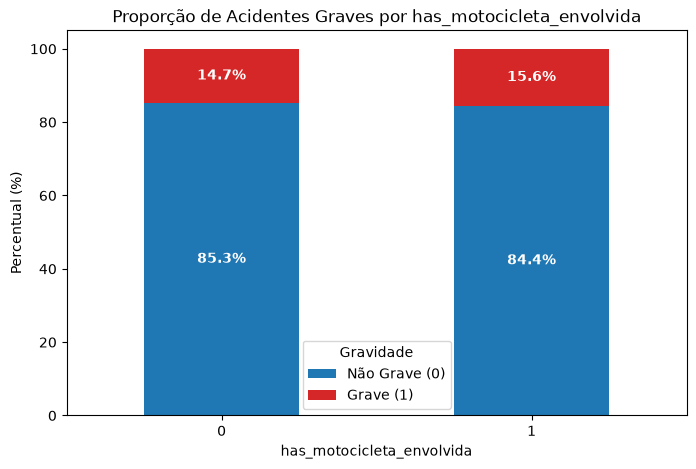

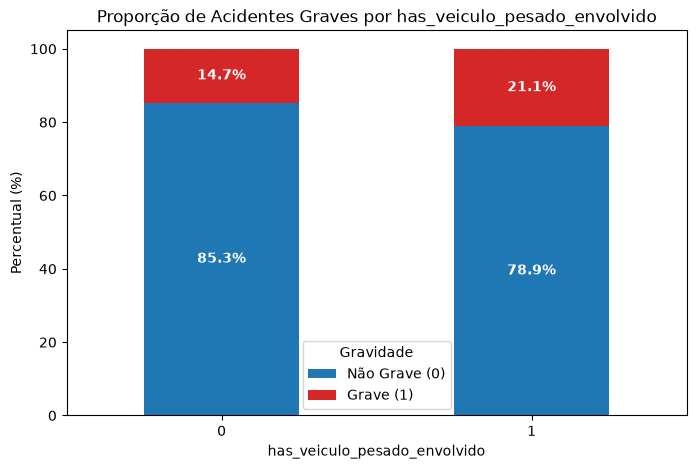

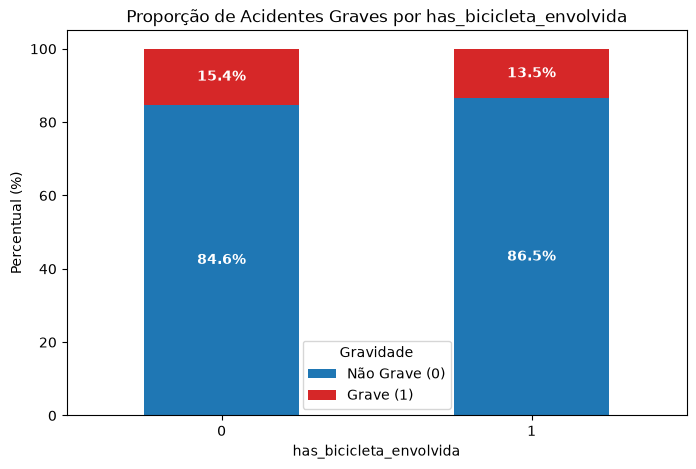

In [15]:
print('Variáveis relacionadas com veículos')
plot_proporcao_gravidade(df_abt, 'has_motocicleta_envolvida')
plot_proporcao_gravidade(df_abt, 'has_veiculo_pesado_envolvido')
plot_proporcao_gravidade(df_abt, 'has_bicicleta_envolvida')

Variáveis relacionadas com características da via


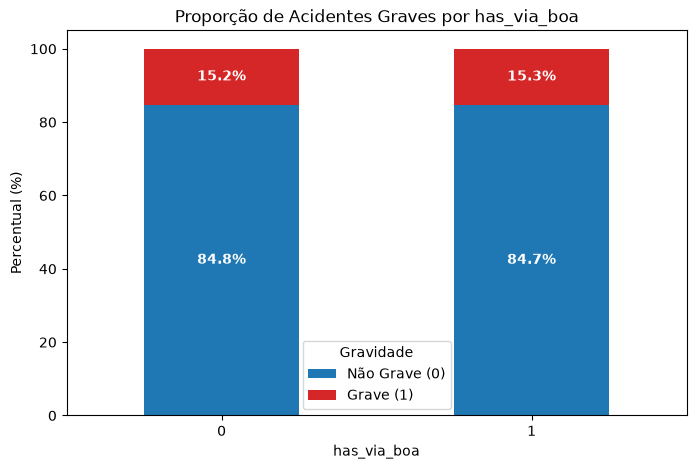

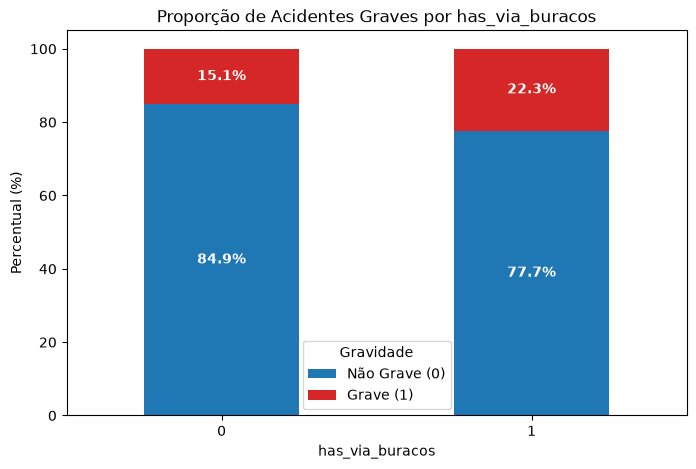

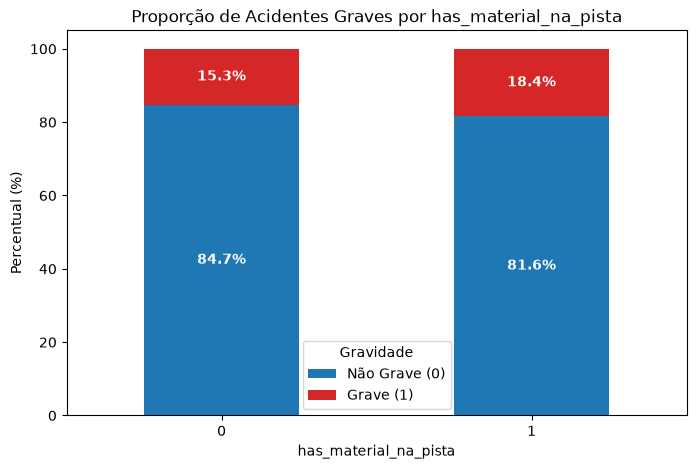

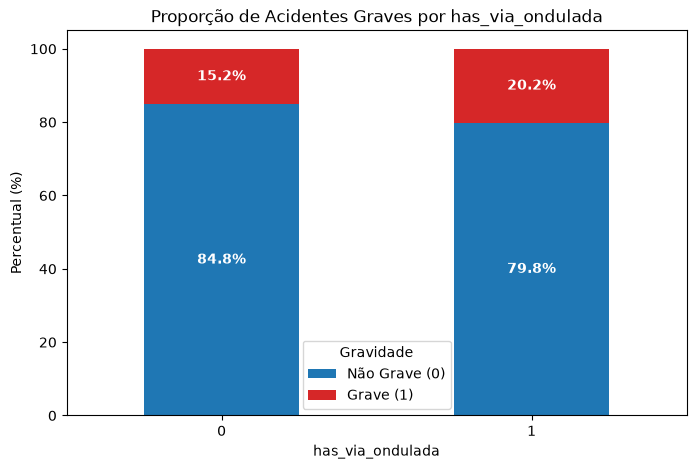

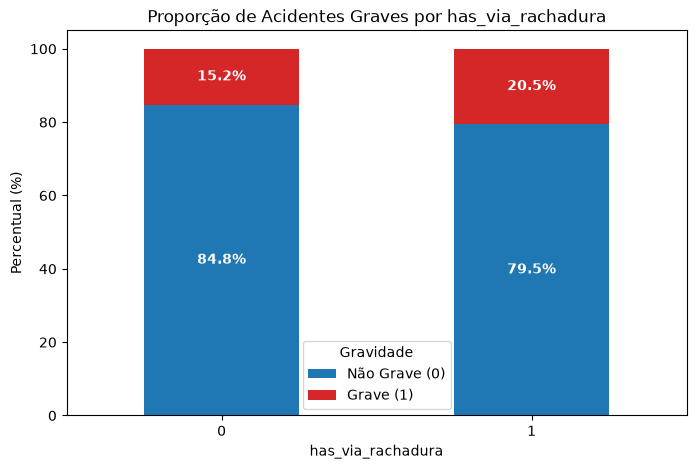

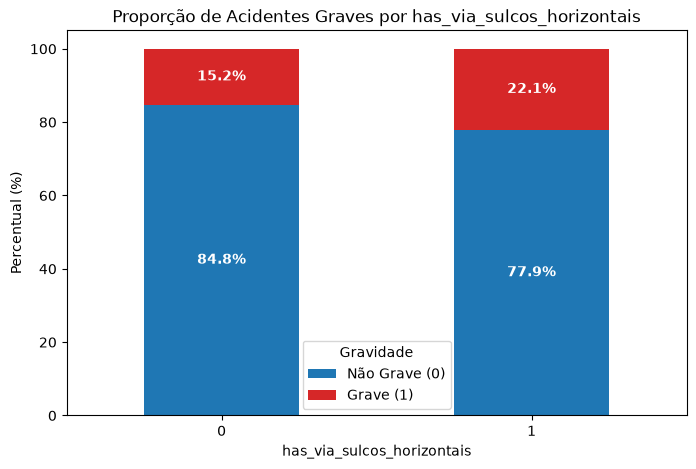

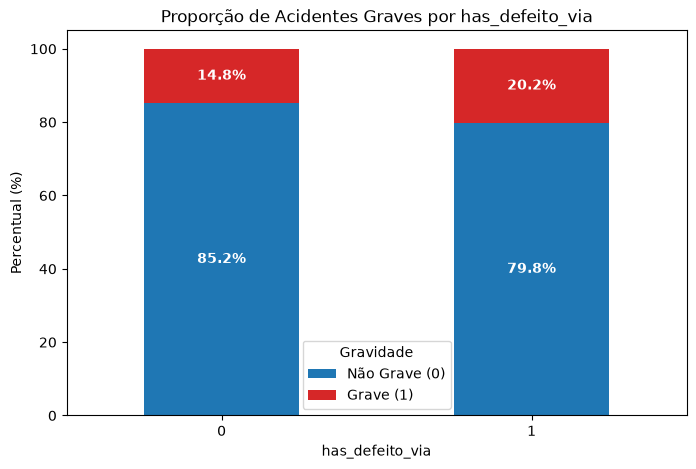

In [16]:
print('Variáveis relacionadas com características da via')
plot_proporcao_gravidade(df_abt, 'has_via_boa')
plot_proporcao_gravidade(df_abt, 'has_via_buracos')
plot_proporcao_gravidade(df_abt, 'has_material_na_pista')
plot_proporcao_gravidade(df_abt, 'has_via_ondulada')
plot_proporcao_gravidade(df_abt, 'has_via_rachadura')
plot_proporcao_gravidade(df_abt, 'has_via_sulcos_horizontais')
plot_proporcao_gravidade(df_abt, 'has_defeito_via')

Variáveis relacionadas com condicões da via


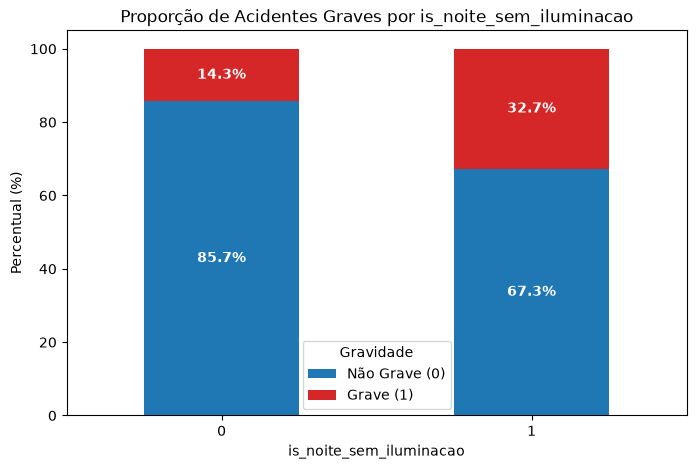

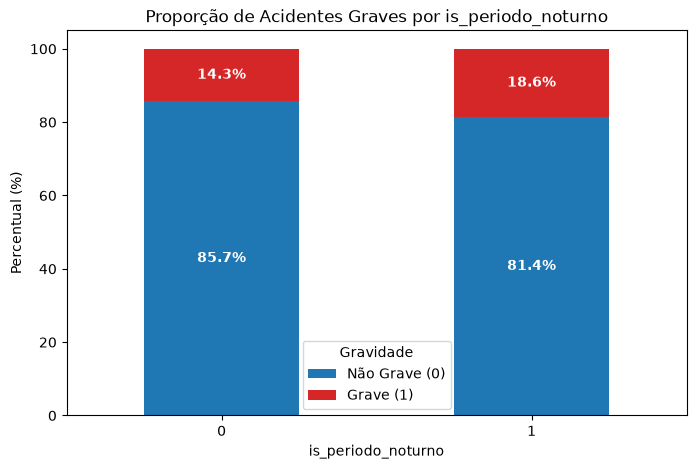

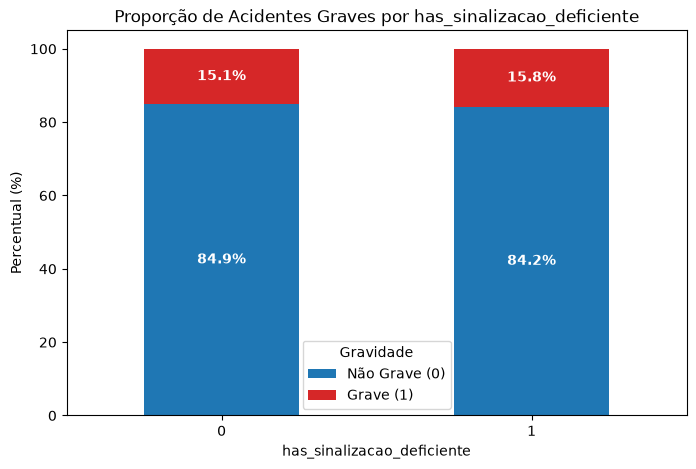

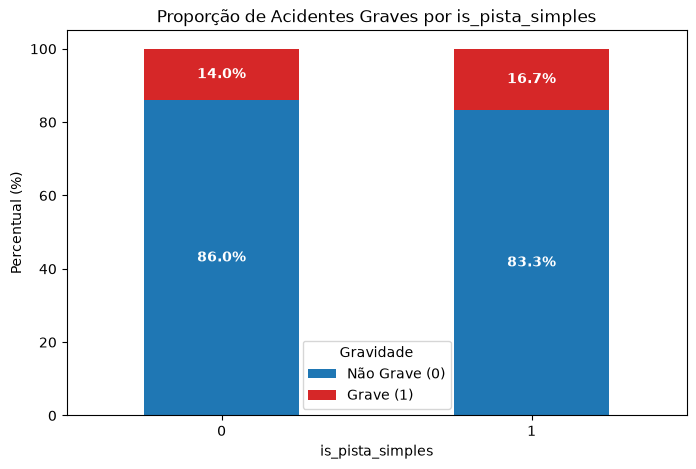

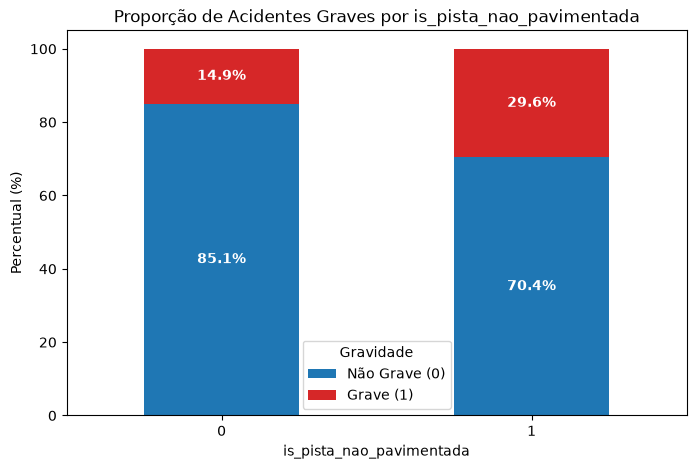

In [17]:
print('Variáveis relacionadas com condicões da via')
plot_proporcao_gravidade(df_abt, 'is_noite_sem_iluminacao')
plot_proporcao_gravidade(df_abt, 'is_periodo_noturno')
plot_proporcao_gravidade(df_abt, 'has_sinalizacao_deficiente')
plot_proporcao_gravidade(df_abt, 'is_pista_simples')
plot_proporcao_gravidade(df_abt, 'is_pista_nao_pavimentada')

Variáveis relacionadas com vítimas


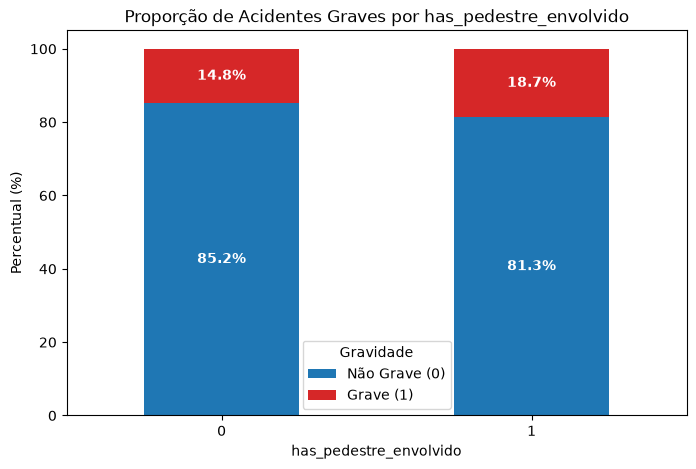

In [18]:
print('Variáveis relacionadas com vítimas')
plot_proporcao_gravidade(df_abt, 'has_pedestre_envolvido')

Variáveis relacionadas com a ocorrência em si


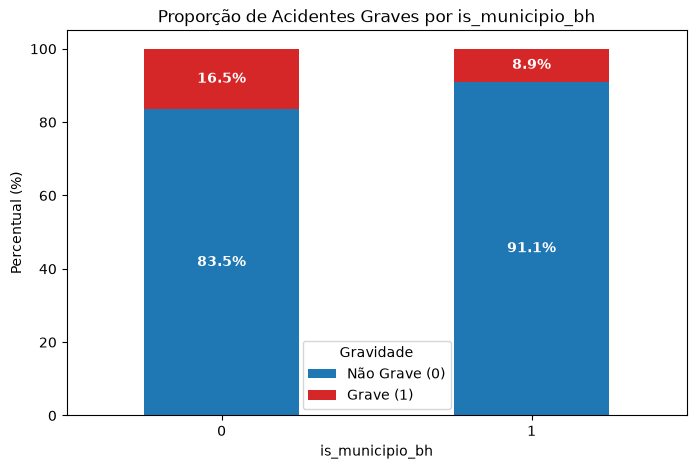

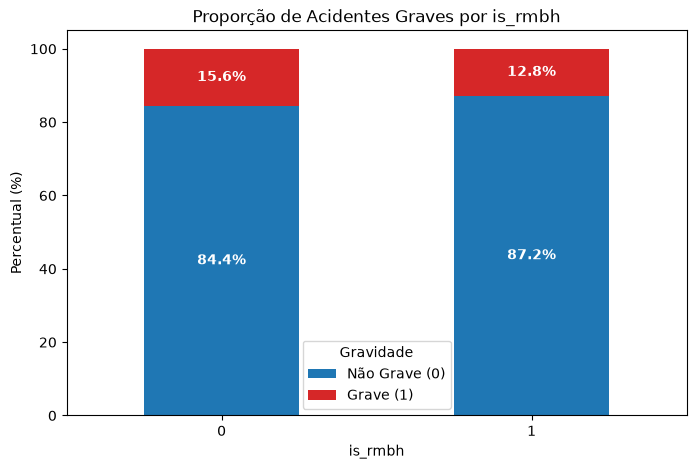

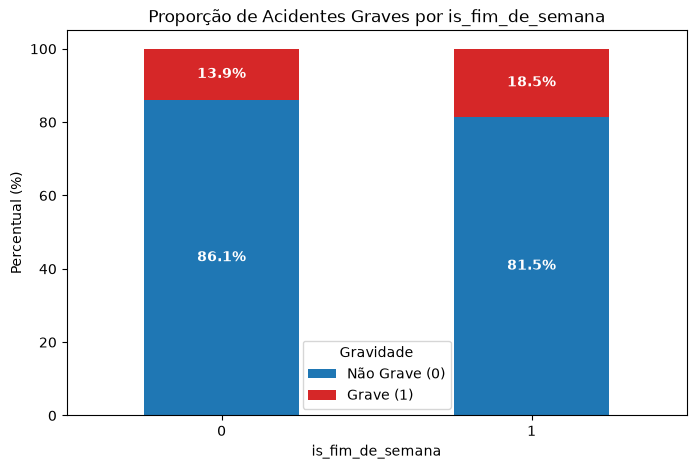

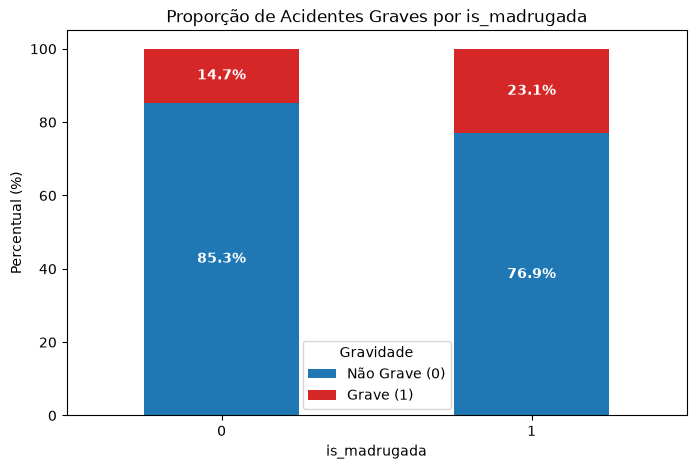

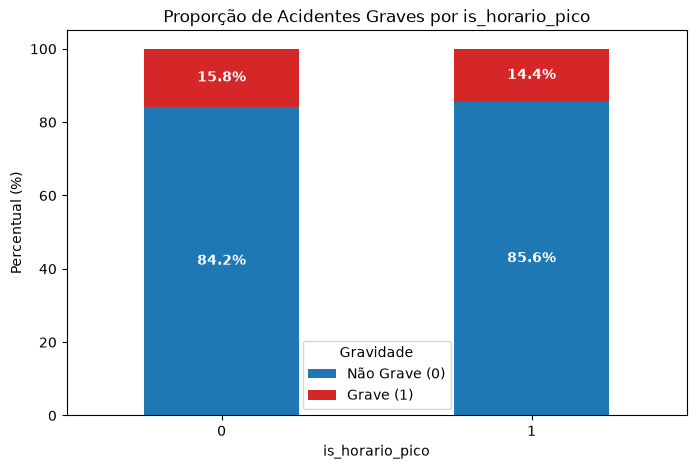

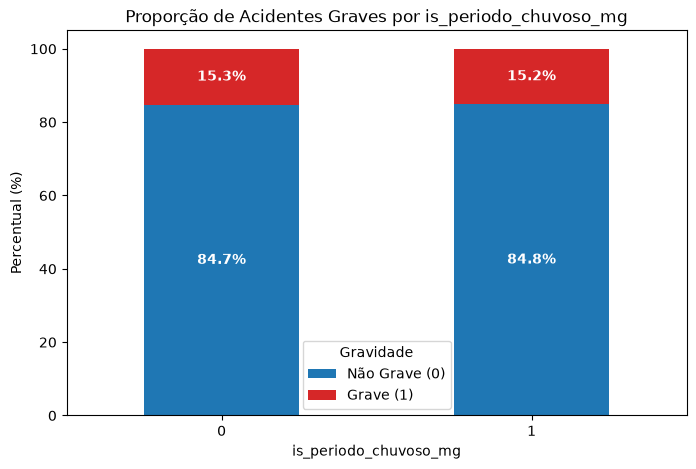

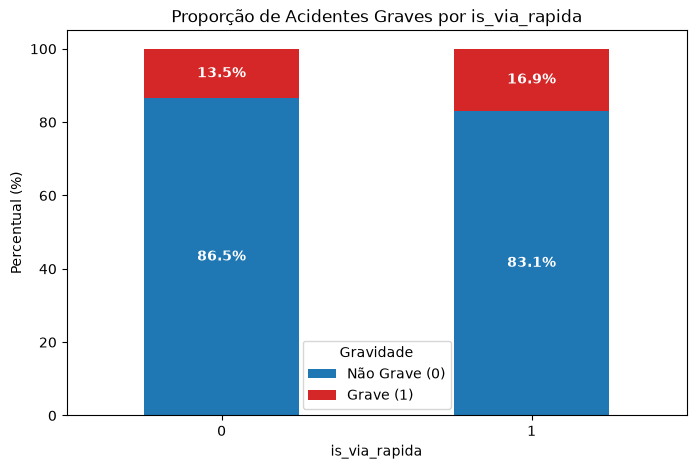

In [19]:
print('Variáveis relacionadas com a ocorrência em si')
plot_proporcao_gravidade(df_abt, 'is_municipio_bh')
plot_proporcao_gravidade(df_abt, 'is_rmbh')
plot_proporcao_gravidade(df_abt, 'is_fim_de_semana')
plot_proporcao_gravidade(df_abt, 'is_madrugada')
plot_proporcao_gravidade(df_abt, 'is_horario_pico')
plot_proporcao_gravidade(df_abt, 'is_periodo_chuvoso_mg')
plot_proporcao_gravidade(df_abt, 'is_via_rapida')

## 2. Distribuição de Variáveis Contínuas

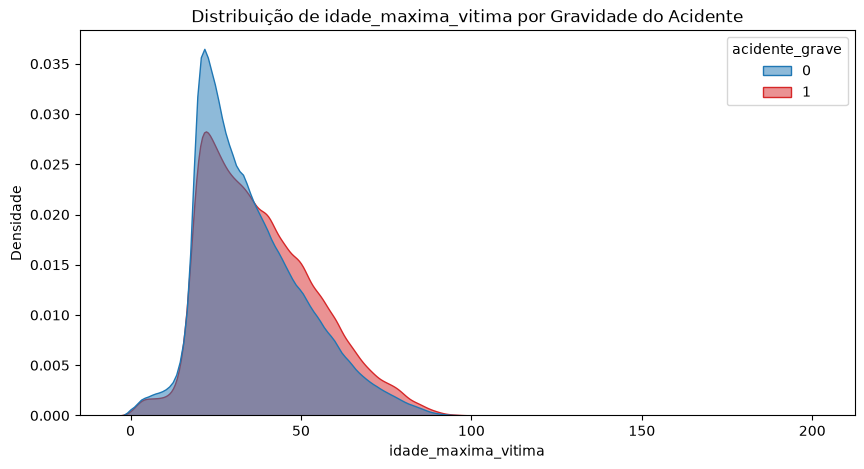

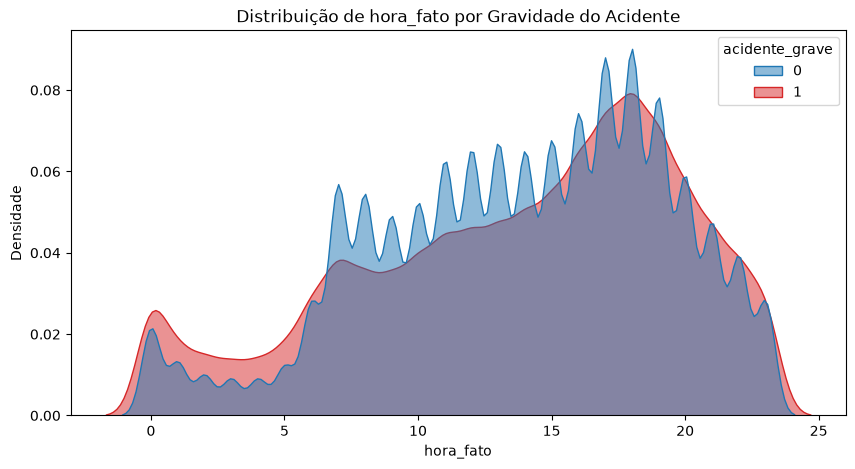

In [20]:
from src.visualization import plot_densidade_numerica

plot_densidade_numerica(df_abt, 'idade_maxima_vitima')
plot_densidade_numerica(df_abt, 'hora_fato')

Observa-se que a medida em que a idade avança, as pessoas mais velhas (observando o atributo `idade_maxima_vitima`) têm maior probabilidade de classificação grave. Assim como, os acidentes graves superam os não-graves a partir das 20 até pouco depois das 5, compreendendo assim o período da noite e da madrugada.

## 3. Heatmap

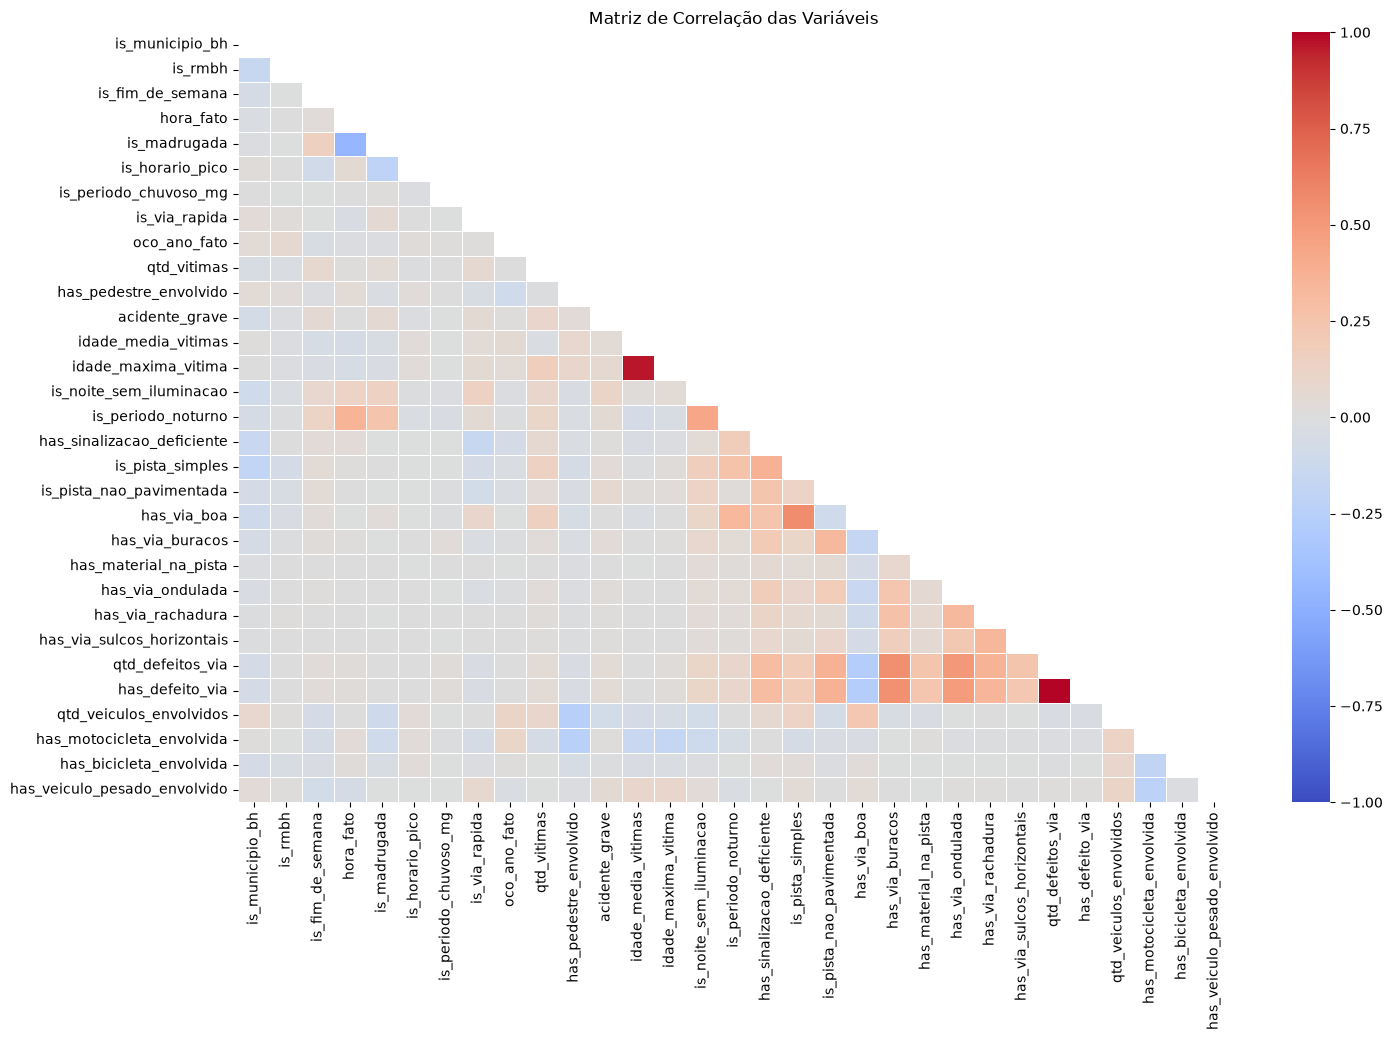

In [21]:
from src.visualization import plot_matriz_correlacao

plot_matriz_correlacao(df_abt)

Observações:
- O gráfico identifica redundâncias nos dados, marcadas pela correlação positiva máxima (em vermelho escuro) entre os atributos `idade_media_vitimas` e `idade_maxima_vitima`, assim como entre `has_defeito_via` e `qtd_defeitos_via`. Para evitar a problemas na fase de modelagem, uma variável de cada um desses pares precisará ser descartada antes da fase de treinamento.
- Do outro lado, verifica-se uma correlação negativa (tons de azul) entre `has_via_boa` e as variáveis que evidenciam problemas de infraestrutura (`has_defeito_via`, `has_via_buracos`, `has_via_ondulada`). Assim como existe uma correlação negativa entre as variáveis `has_motocicleta_envolvida` e `has_bicicleta_envolvida` e a variável de veículos pesados (`has_veiculo_pesado_envolvido`), evidenciando as diferentes naturezas desses sinistros. 
- As relações da variável alvo `acidente_grave` com as outras características da base exibem apenas tons neutros, com algumas pequenas variações para maior correlação com atributos como `is_noite_sem_iluminacao` e para menor com o atributo `qtd_veiculos_envolvidos`. Isso mostra que não existem relações preditivas simples ou estritamente lineares. Consequentemente, modelos como Regressão Logística tenderão a apresentar baixa eficiência, tornando obrigatória a adoção de algoritmos não lineares (como Random Forest, XGBoost ou Redes Neurais) capazes de capturar interações complexas entre múltiplas variáveis.

## 4. Análise Geoespacial 

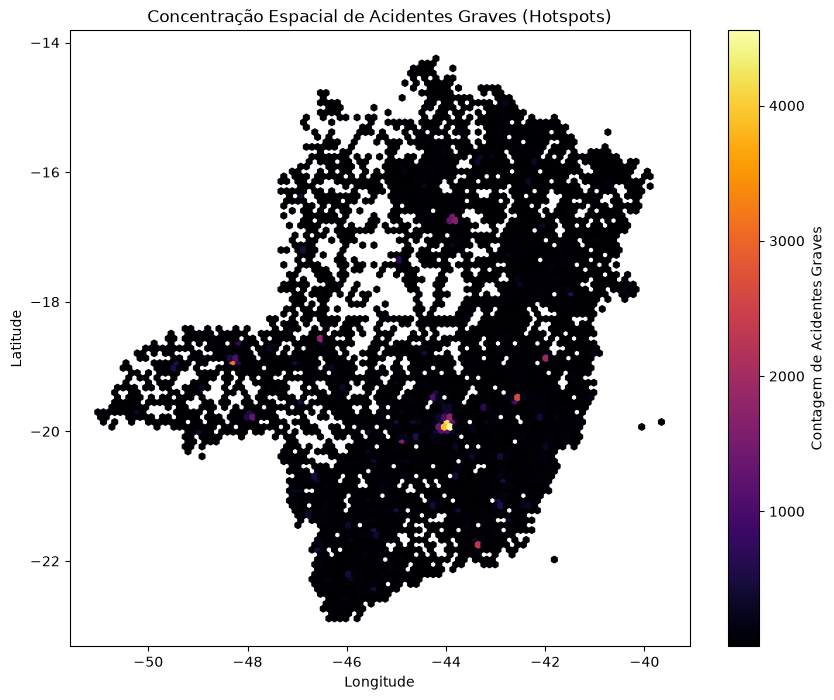

In [22]:
from src.visualization import plot_mapa_calor_hexagonal

plot_mapa_calor_hexagonal(df_abt)

A análise geoespacial mostra uma distribuição altamente assimétrica dos acidentes graves no estado de Minas Gerais. Observa-se a formação de um maciço hotspot (ponto quente) de altíssima densidade, superando a marca de 2.000 acidentes graves agrupados, localizado nas proximidades da latitude -20 e longitude -44. Essas coordenadas correspondem, geograficamente, à Região Metropolitana de Belo Horizonte (RMBH) e à capital. A esmagadora concentração de ocorrências severas nesta localidade específica valida a pertinência das variáveis `is_municipio_bh` e `is_rmbh` no modelo, sugerindo que o volume de tráfego urbano intenso é um dos principais catalisadores absolutos de acidentes com vítimas na base de dados.   

# Modelagem

## 1. Modelagem Inicial: Baseline com Random Forest

Para estabelecer uma linha de base (*baseline*) de desempenho, iniciaremos a modelagem com o algoritmo **Random Forest**. Por se tratar de um conjunto de árvores de decisão (*ensemble*), este modelo lida bem com relações não lineares e é robusto a *outliers*. 

O principal desafio desta base de dados de acidentes de trânsito é o **forte desbalanceamento de classes** (ocorrências leves/moderadas são a esmagadora maioria em comparação aos acidentes graves). Para mitigar este problema nesta primeira etapa, utilizaremos o parâmetro `class_weight='balanced'`, que penaliza o modelo de forma mais severa quando ele erra a classe minoritária (acidente grave), ajustando os pesos inversamente proporcionais à frequência das classes.

=== Relatório de Desempenho ===
               precision    recall  f1-score   support

Leve/Moderado       0.91      0.64      0.75    158483
        Grave       0.24      0.64      0.35     28566

     accuracy                           0.64    187049
    macro avg       0.58      0.64      0.55    187049
 weighted avg       0.81      0.64      0.69    187049



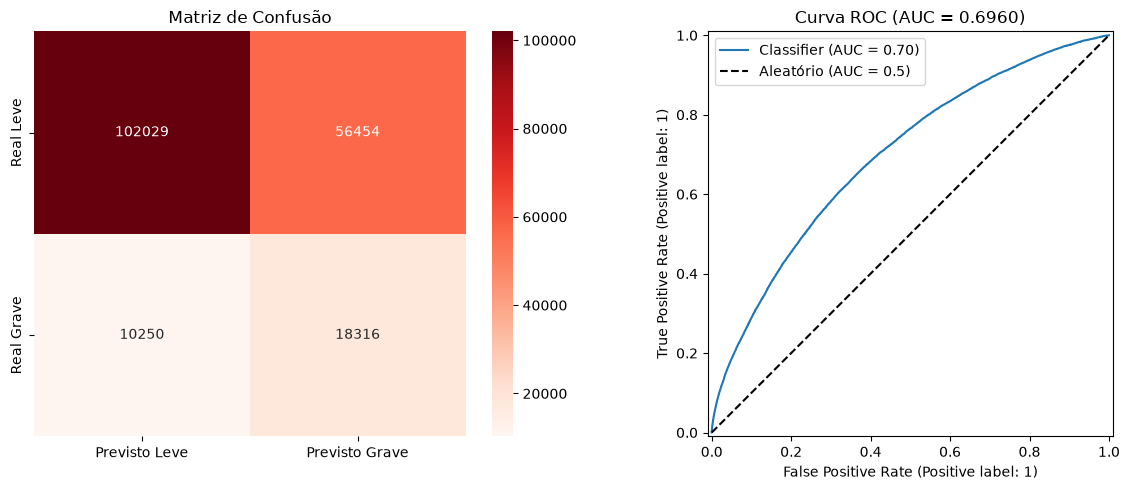

In [23]:
from src.modeling import (
    train_random_forest_baseline,
    clean_and_select_features,
    encode_categorical_features,
    prepare_train_test_data,
    evaluate_severity_model
)

# 1. Limpeza e remoção de redundâncias
df_abt_clean = clean_and_select_features(df_abt)

# 2. Codificação das variáveis categóricas (Resolve o erro 'RUA')
df_abt_encoded = encode_categorical_features(df_abt_clean)

# 3. Divisão Treino/Teste (agora usando o dataframe encodado)
X_train, X_test, y_train, y_test = prepare_train_test_data(df_abt_encoded)

# 4. Treinamento da baseline
rf_model = train_random_forest_baseline(X_train, y_train)

# 5. Avaliação de métricas
evaluate_severity_model(rf_model, X_test, y_test)

### 1.1. Análise do Trade-off de Decisão (Threshold Tuning)

A avaliação da *baseline* com o limiar de decisão padrão ($Threshold = 0.50$) revelou um desafio inerente ao contexto de saúde pública e segurança viária: o modelo apresentou uma quantidade perigosa de **Falsos Negativos (Falsos Leves)**. Na prática, isso significa que vítimas de acidentes graves poderiam ser sub-priorizadas no despacho de ambulâncias e equipes de resgate.

Para alinhar o modelo aos objetivos de negócio (salvar vidas e priorizar recursos críticos), vamos analisar o comportamento das métricas ao ajustarmos o limiar de decisão. Reduzir o ponto de corte forçará o modelo a ser mais "sensível" aos acidentes graves, aumentando o *Recall*, assumindo a contrapartida de gerar mais alertas falsos (reduzindo a *Precisão*).

In [15]:
from src.modeling import evaluate_decision_thresholds

# 1. Definição da lista de limiares para teste
custom_thresholds = [0.50, 0.45, 0.40, 0.35, 0.30, 0.25]

# 2. Execução da avaliação comparativa
threshold_comparison_df = evaluate_decision_thresholds(
    model=rf_model, 
    X_test=X_test, 
    y_test=y_test, 
    thresholds=custom_thresholds
)

# 3. Exibição da tabela de trade-off
display(threshold_comparison_df)

,Limiar (Threshold),Verdadeiros Graves (TP),Falsos Leves (FN),Falsos Alertas (FP),Precisão (Grave),Recall (Grave),F1-Score (Grave)
0,0.50,7351,4349,21562,0.2542,0.6283,0.3620
1,0.45,8590,3110,28801,0.2297,0.7342,0.3500
2,0.40,9545,2155,35840,0.2103,0.8158,0.3344
3,0.35,10652,1048,46688,0.1858,0.9104,0.3086
4,0.30,11367,333,55644,0.1696,0.9715,0.2888
5,0.25,11563,137,59676,0.1623,0.9883,0.2788


### 1.2. Conclusão da Baseline e Próximos Passos

A análise dos limiares evidencia o clássico *trade-off* entre Precisão e Recall. Ao reduzirmos o limiar para `0.35`, conseguimos elevar o *Recall* para mais de 90% (mitigando drasticamente os Falsos Negativos). No entanto, o custo operacional é altíssimo: a precisão cai drasticamente e o volume de Falsos Positivos (*Falsos Alertas*) ultrapassa a marca de 46 mil, o que seria insustentável para a frota de resgate (SAMU/Bombeiros).